# AI-Driven Cyber Threat Awareness and Detection Prototype

**Name:** Srishti Kainth
**Roll No:** 2301730175
**Course:** AI in Cyber Security Lab (ENSP355) - Lab Assignment 01 (Unit 1)
**Submitted To:** Dr. Monika Khatkar
**University:** K.R. Mangalam University

This notebook runs the full project, task by task, and shows the output and plots of each step.
The same code is also available as separate `.py` files in this `src/` folder.

In [1]:
# The .py scripts find the data/ and outputs/ folders using __file__.
# A notebook has no __file__, so we point it at this src/ folder.
from pathlib import Path
__file__ = str(Path.cwd() / "notebook.py")
%matplotlib inline

## Task 1: Workspace Bootstrap and Environment Setup

Quick sanity check: imports every required library, prints its version,
and trains a tiny model so we know the setup really works.

In [2]:
import sys

import matplotlib
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression

print(f"Python       : {sys.version.split()[0]}")
print(f"numpy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")
print(f"seaborn      : {sns.__version__}")

X, y = make_classification(n_samples=200, n_features=5, random_state=0)
score = LogisticRegression().fit(X, y).score(X, y)
print(f"\nSmoke test: tiny logistic regression trained, accuracy = {score:.2f}")
print("Environment is ready.")

Python       : 3.13.16
numpy        : 2.5.3
pandas       : 3.0.5
scikit-learn : 1.9.1
matplotlib   : 3.11.2
seaborn      : 0.13.2

Smoke test: tiny logistic regression trained, accuracy = 0.95
Environment is ready.


## Dataset Generation

Creates the login-attempt dataset used in this project.
Why a generated dataset?
Real login logs from companies are private and almost never shared.
So I built a small simulator that copies how real login logs look:
most logins are normal, and a smaller share come from known attack
patterns (brute force, credential stuffing, insider data theft).
I also add a few messy things on purpose (missing values, noise,
overlap between classes) so the data is not "too clean" and the
models have to actually learn something.
Output:
data/login_events.csv          -> main dataset (train + test)
data/foreign_travellers.csv    -> extra set of GENUINE users logging in
from abroad, used in Task 5 (bias test)

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd

SEED = 42
rng = np.random.default_rng(SEED)

DATA_DIR = Path(__file__).resolve().parent.parent / "data"
DATA_DIR.mkdir(exist_ok=True)


def normal_logins(n, location_probs=(0.62, 0.36, 0.02)):
    """Everyday logins by real employees."""
    return pd.DataFrame({
        "user_role": rng.choice(["employee", "admin", "contractor", "guest"], n,
                                p=[0.70, 0.08, 0.15, 0.07]),
        "device_type": rng.choice(["desktop", "mobile", "unknown"], n, p=[0.60, 0.37, 0.03]),
        "location": rng.choice(["office", "home", "foreign"], n, p=location_probs),
        "auth_method": rng.choice(["sso", "password", "otp"], n, p=[0.50, 0.30, 0.20]),
        # people mostly log in during the working day
        "hour_of_day": np.clip(rng.normal(13, 3.5, n).round(), 0, 23).astype(int),
        "failed_attempts_1h": rng.poisson(0.4, n),
        "session_duration_min": np.clip(rng.normal(45, 20, n), 1, None).round(1),
        "data_downloaded_mb": np.clip(rng.lognormal(3.0, 0.9, n), 0, None).round(1),
        "distinct_ips_24h": rng.poisson(1.2, n) + 1,
        "is_vpn": rng.choice([0, 1], n, p=[0.80, 0.20]),
        "attack_type": "none",
        "label": 0,
    })


def brute_force(n):
    """Attacker guessing passwords again and again."""
    df = normal_logins(n, location_probs=(0.05, 0.25, 0.70))
    df["auth_method"] = "password"
    df["device_type"] = rng.choice(["desktop", "unknown"], n, p=[0.4, 0.6])
    df["hour_of_day"] = rng.choice(list(range(0, 6)) + list(range(20, 24)), n)
    df["failed_attempts_1h"] = rng.poisson(9, n)
    df["session_duration_min"] = np.clip(rng.normal(6, 5, n), 1, None).round(1)
    df["attack_type"] = "brute_force"
    df["label"] = 1
    return df


def credential_stuffing(n):
    """Leaked passwords tried from many different IPs."""
    df = normal_logins(n, location_probs=(0.02, 0.28, 0.70))
    df["failed_attempts_1h"] = rng.poisson(3, n)
    df["distinct_ips_24h"] = rng.poisson(7, n) + 2
    df["is_vpn"] = rng.choice([0, 1], n, p=[0.35, 0.65])
    df["session_duration_min"] = np.clip(rng.normal(12, 8, n), 1, None).round(1)
    df["attack_type"] = "credential_stuffing"
    df["label"] = 1
    return df


def insider_exfiltration(n):
    """Valid user (often a contractor) pulling out large amounts of data."""
    df = normal_logins(n, location_probs=(0.45, 0.45, 0.10))
    df["user_role"] = rng.choice(["contractor", "employee", "admin"], n, p=[0.55, 0.30, 0.15])
    df["hour_of_day"] = np.clip(rng.normal(21, 3, n).round(), 0, 23).astype(int)
    df["data_downloaded_mb"] = np.clip(rng.lognormal(6.2, 0.7, n), 0, None).round(1)
    df["session_duration_min"] = np.clip(rng.normal(95, 35, n), 1, None).round(1)
    df["attack_type"] = "insider_exfiltration"
    df["label"] = 1
    return df


def add_missing_values(df, cols, frac=0.03):
    """Real logs have gaps (agent crashed, field not captured, etc.)."""
    df = df.copy()
    for col in cols:
        idx = rng.choice(df.index, int(len(df) * frac), replace=False)
        df.loc[idx, col] = np.nan
    return df


def main():
    # Sampling bias on purpose: very few normal logins come from "foreign",
    # while most attacks do. This is what a real company's history often
    # looks like, and it is exactly what Task 5 studies.
    parts = [
        normal_logins(4000),
        brute_force(420),
        credential_stuffing(380),
        insider_exfiltration(200),
    ]
    df = pd.concat(parts, ignore_index=True)

    # A small amount of "grey zone" noise: some normal users who forgot
    # their password at night, some attacks that look calm.
    noisy = rng.choice(df.index, int(len(df) * 0.04), replace=False)
    df.loc[noisy, "failed_attempts_1h"] = rng.poisson(4, len(noisy))

    df = add_missing_values(df, ["device_type", "session_duration_min",
                                 "data_downloaded_mb", "distinct_ips_24h"])

    df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
    df.insert(0, "event_id", [f"EVT{100000 + i}" for i in range(len(df))])
    df.to_csv(DATA_DIR / "login_events.csv", index=False)

    # Separate group: 300 genuine employees working from abroad.
    # Their behaviour is completely normal; only the location is different.
    travellers = normal_logins(300, location_probs=(0.0, 0.0, 1.0))
    travellers.insert(0, "event_id", [f"TRV{500000 + i}" for i in range(300)])
    travellers.to_csv(DATA_DIR / "foreign_travellers.csv", index=False)

    print(f"login_events.csv       -> {len(df)} rows "
          f"({df['label'].mean():.1%} suspicious)")
    print(f"foreign_travellers.csv -> {len(travellers)} rows (all genuine)")


if __name__ == "__main__":
    main()

login_events.csv       -> 5000 rows (20.0% suspicious)
foreign_travellers.csv -> 300 rows (all genuine)


## Shared Preprocessing Helpers

Shared helpers used by every task script: paths, loading the data,
and the preprocessing pipeline (missing values, encoding, scaling).
Keeping this in one place means every model sees the data in exactly
the same way, so the ML vs DL comparison is fair.

In [4]:
from pathlib import Path

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path(__file__).resolve().parent.parent
DATA_DIR = ROOT / "data"
PLOT_DIR = ROOT / "outputs" / "plots"
RESULT_DIR = ROOT / "outputs" / "results"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42

CATEGORICAL = ["user_role", "device_type", "location", "auth_method"]
NUMERIC = ["hour_of_day", "failed_attempts_1h", "session_duration_min",
           "data_downloaded_mb", "distinct_ips_24h", "is_vpn"]
TARGET = "label"


def load_data():
    path = DATA_DIR / "login_events.csv"
    if not path.exists():
        raise FileNotFoundError(
            "Dataset not found. Run `python src/generate_data.py` first."
        )
    return pd.read_csv(path)


def build_preprocessor(categorical=CATEGORICAL, numeric=NUMERIC):
    """Missing values -> encoding -> scaling, all inside one sklearn object."""
    numeric_steps = Pipeline([
        ("impute", SimpleImputer(strategy="median")),   # median is safe with outliers
        ("scale", StandardScaler()),
    ])
    categorical_steps = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("num", numeric_steps, numeric),
        ("cat", categorical_steps, categorical),
    ])


def split(df):
    """Stratified 75/25 split so both sets keep the same attack ratio."""
    X = df[CATEGORICAL + NUMERIC]
    y = df[TARGET]
    return train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)

## Task 2: Cyber Security Threat Landscape Analysis

Exploratory data analysis on the login events. The goal is to find
which signals actually separate normal logins from suspicious ones,
before any model is trained.

In [5]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from common import CATEGORICAL, NUMERIC, PLOT_DIR, RESULT_DIR, load_data

sns.set_theme(style="whitegrid")
PALETTE = {"Normal": "#4C72B0", "Suspicious": "#C44E52"}


def save(fig, name):
    fig.tight_layout()
    fig.savefig(PLOT_DIR / name, dpi=150)
    plt.close(fig)
    print(f"  saved plots/{name}")


def main():
    df = load_data()
    df["status"] = df["label"].map({0: "Normal", 1: "Suspicious"})

    # ---- 1. Basic overview -------------------------------------------------
    print(f"Rows: {len(df)}, Columns: {df.shape[1]}")
    print("\nMissing values per column:")
    print(df.isna().sum()[df.isna().sum() > 0])
    print("\nClass balance:")
    print(df["status"].value_counts(normalize=True).round(3))

    # ---- 2. Threat indicators: mean of each feature by class --------------
    summary = df.groupby("status")[NUMERIC].mean().T.round(2)
    summary["ratio_susp_vs_normal"] = (summary["Suspicious"] / summary["Normal"]).round(2)
    summary = summary.sort_values("ratio_susp_vs_normal", ascending=False)
    summary.to_csv(RESULT_DIR / "threat_indicators.csv")
    print("\nAverage value by class (top threat indicators first):")
    print(summary)

    # ---- Plot 1: normal vs suspicious count --------------------------------
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.countplot(data=df, x="status", hue="status", palette=PALETTE, legend=False, ax=ax)
    ax.set_title("Normal vs Suspicious login events")
    ax.set_xlabel("")
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom")
    save(fig, "01_class_balance.png")

    # ---- Plot 2: frequency of each type of suspicious activity -------------
    attacks = df[df["label"] == 1]["attack_type"].value_counts()
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.barplot(x=attacks.values, y=attacks.index, color="#C44E52", ax=ax)
    ax.set_title("Frequency of suspicious activity types")
    ax.set_xlabel("Number of events")
    ax.set_ylabel("")
    save(fig, "02_attack_type_frequency.png")

    # ---- Plot 3: distribution of attack-related features -------------------
    features = ["failed_attempts_1h", "distinct_ips_24h", "data_downloaded_mb",
                "session_duration_min", "hour_of_day"]
    fig, axes = plt.subplots(2, 3, figsize=(13, 7))
    for ax, col in zip(axes.flat, features):
        data = df.copy()
        log_scale = col == "data_downloaded_mb"   # downloads are heavily skewed
        sns.histplot(data=data, x=col, hue="status", palette=PALETTE, element="step",
                     stat="density", common_norm=False, bins=30, log_scale=log_scale, ax=ax)
        ax.set_title(col)
    axes.flat[-1].axis("off")
    fig.suptitle("Distribution of attack-related features: Normal vs Suspicious", y=1.01)
    save(fig, "03_feature_distributions.png")

    # ---- Plot 4: login hour (when do attacks happen?) ----------------------
    hourly = df.groupby(["hour_of_day", "status"]).size().unstack(fill_value=0)
    fig, ax = plt.subplots(figsize=(9, 4))
    hourly.plot(ax=ax, color=[PALETTE["Normal"], PALETTE["Suspicious"]], marker="o")
    ax.set_title("Login events by hour of day")
    ax.set_xlabel("Hour (0-23)")
    ax.set_ylabel("Events")
    save(fig, "04_hourly_pattern.png")

    # ---- Plot 5: suspicious rate by category -------------------------------
    fig, axes = plt.subplots(1, 4, figsize=(15, 4))
    for ax, col in zip(axes, CATEGORICAL):
        rate = df.groupby(col)["label"].mean().sort_values(ascending=False) * 100
        sns.barplot(x=rate.index, y=rate.values, color="#DD8452", ax=ax)
        ax.set_title(f"% suspicious by {col}")
        ax.set_ylabel("% suspicious")
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=30)
    save(fig, "05_suspicious_rate_by_category.png")

    # ---- Plot 6: correlation heatmap ---------------------------------------
    corr = df[NUMERIC + ["label"]].corr()
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
    ax.set_title("Correlation between numeric features and label")
    save(fig, "06_correlation_heatmap.png")

    # numbers that go into the report
    foreign = df[df["location"] == "foreign"]
    print(f"\nShare of 'foreign' logins that are suspicious: {foreign['label'].mean():.1%}")
    print(f"Share of all suspicious events from 'foreign':  "
          f"{(df[df.label == 1]['location'] == 'foreign').mean():.1%}")


if __name__ == "__main__":
    main()

Rows: 5000, Columns: 14

Missing values per column:
device_type             150
session_duration_min    150
data_downloaded_mb      150
distinct_ips_24h        150
dtype: int64

Class balance:
status
Normal        0.8
Suspicious    0.2
Name: proportion, dtype: float64

Average value by class (top threat indicators first):
status                Normal  Suspicious  ratio_susp_vs_normal
failed_attempts_1h      0.55        4.85                  8.82
data_downloaded_mb     30.53      136.65                  4.48
distinct_ips_24h        2.22        4.83                  2.18
is_vpn                  0.19        0.36                  1.89
hour_of_day            13.15       13.40                  1.02
session_duration_min   45.41       26.46                  0.58


  saved plots/01_class_balance.png
  saved plots/02_attack_type_frequency.png


  saved plots/03_feature_distributions.png


  saved plots/04_hourly_pattern.png


  saved plots/05_suspicious_rate_by_category.png


  saved plots/06_correlation_heatmap.png

Share of 'foreign' logins that are suspicious: 87.9%
Share of all suspicious events from 'foreign':  56.0%


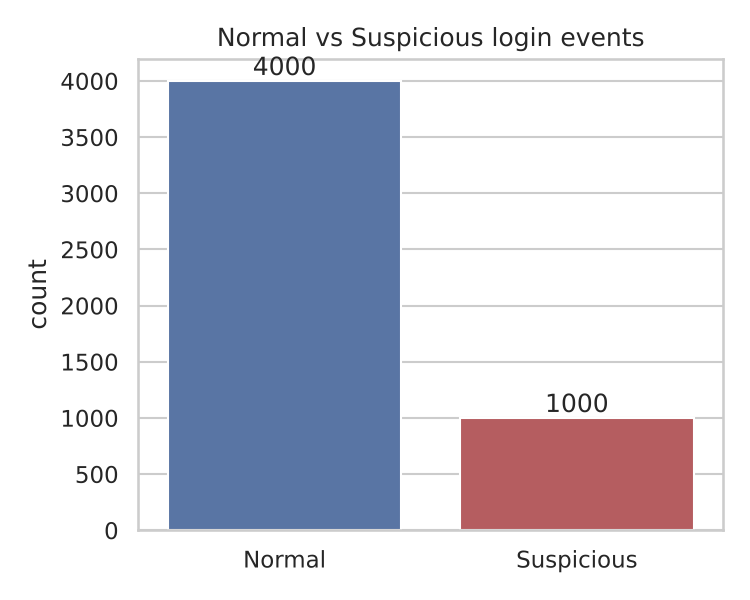

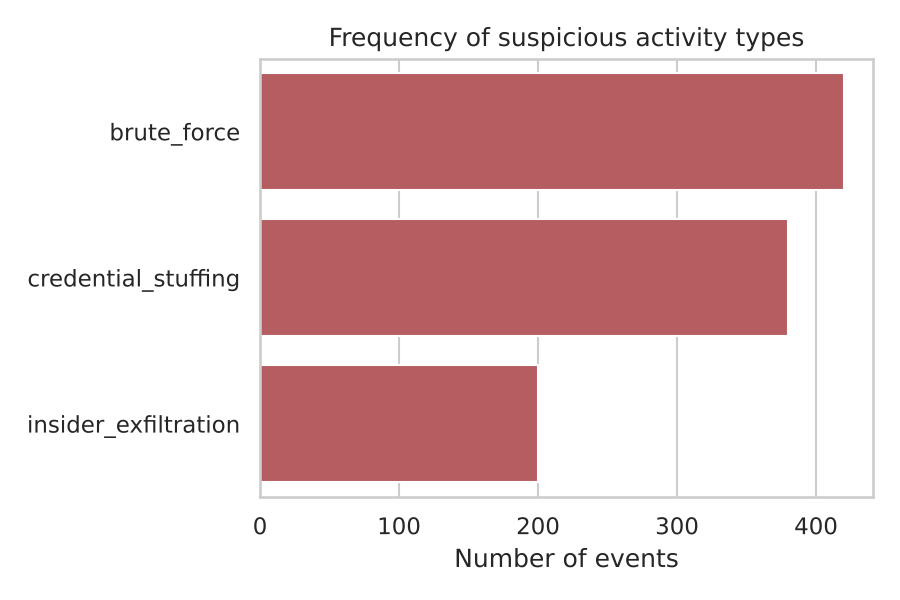

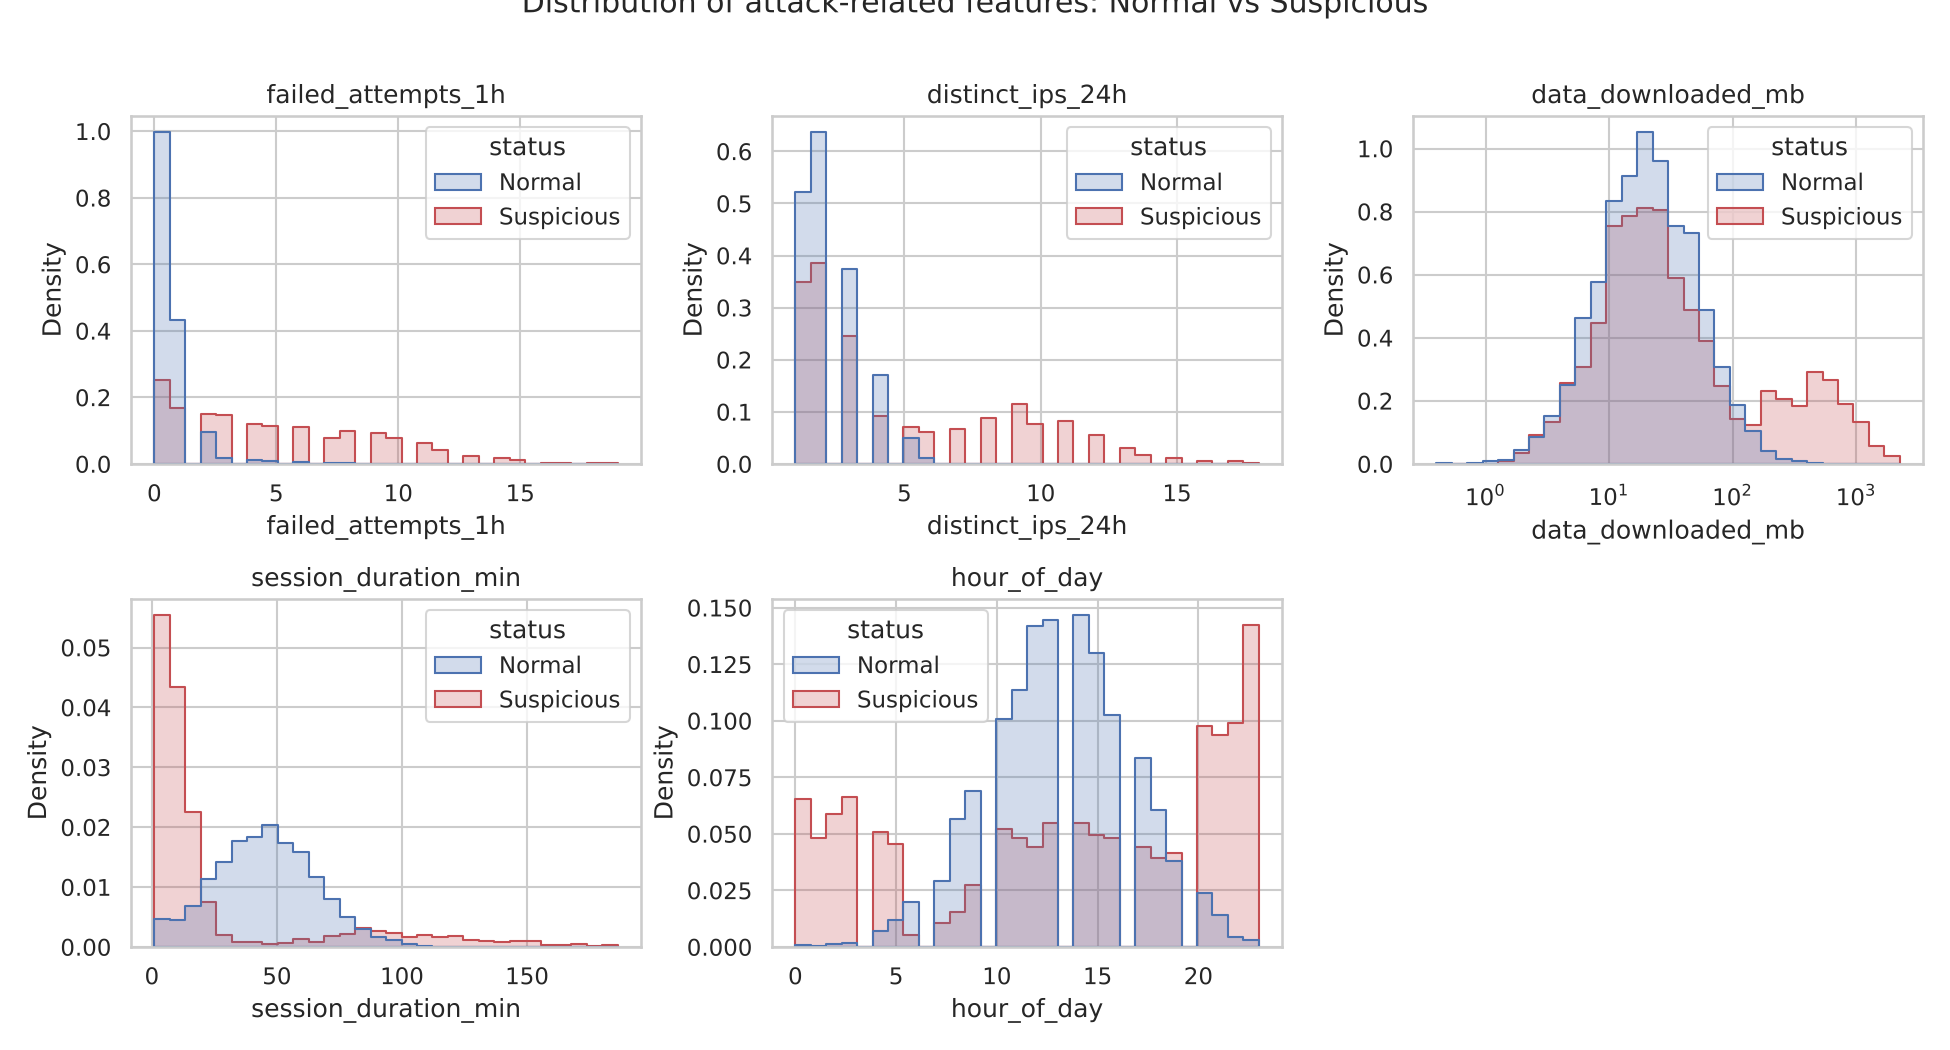

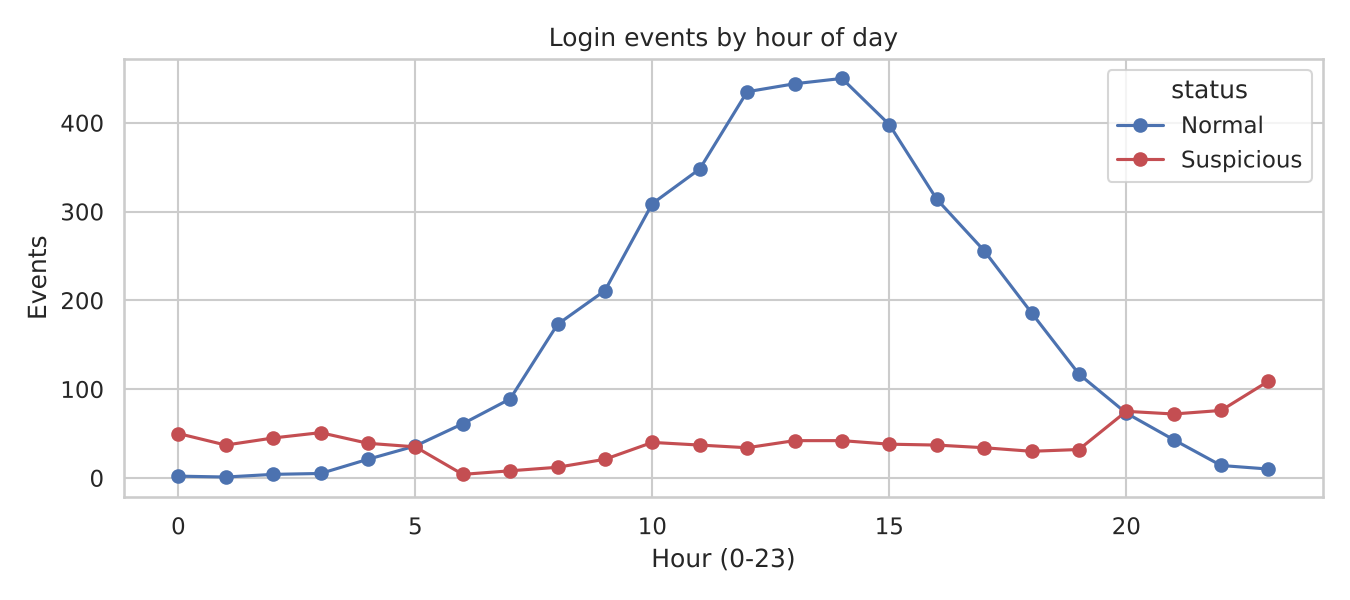

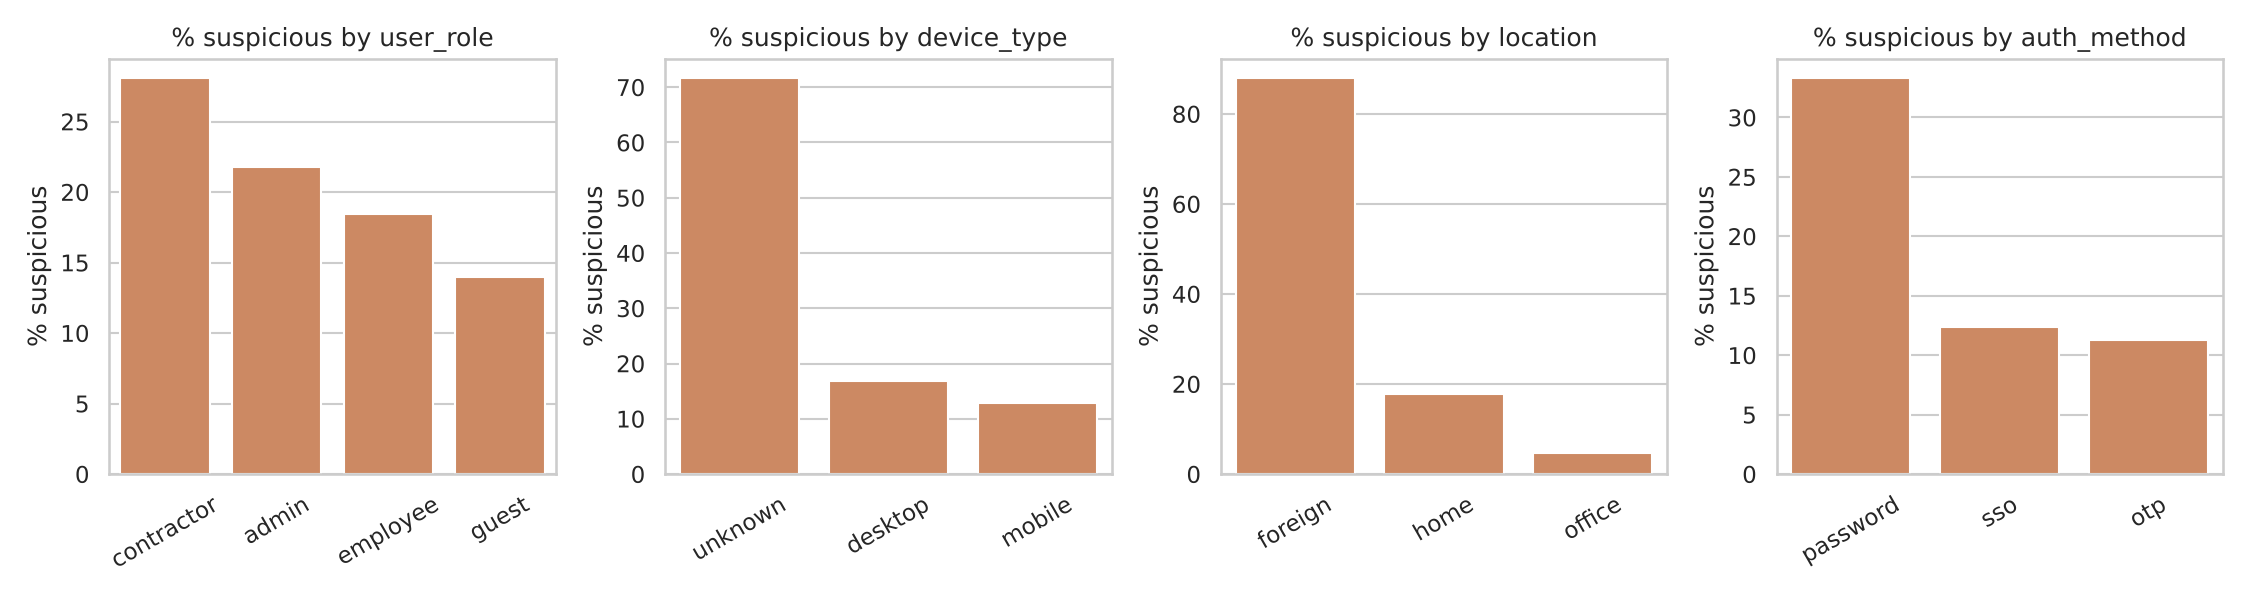

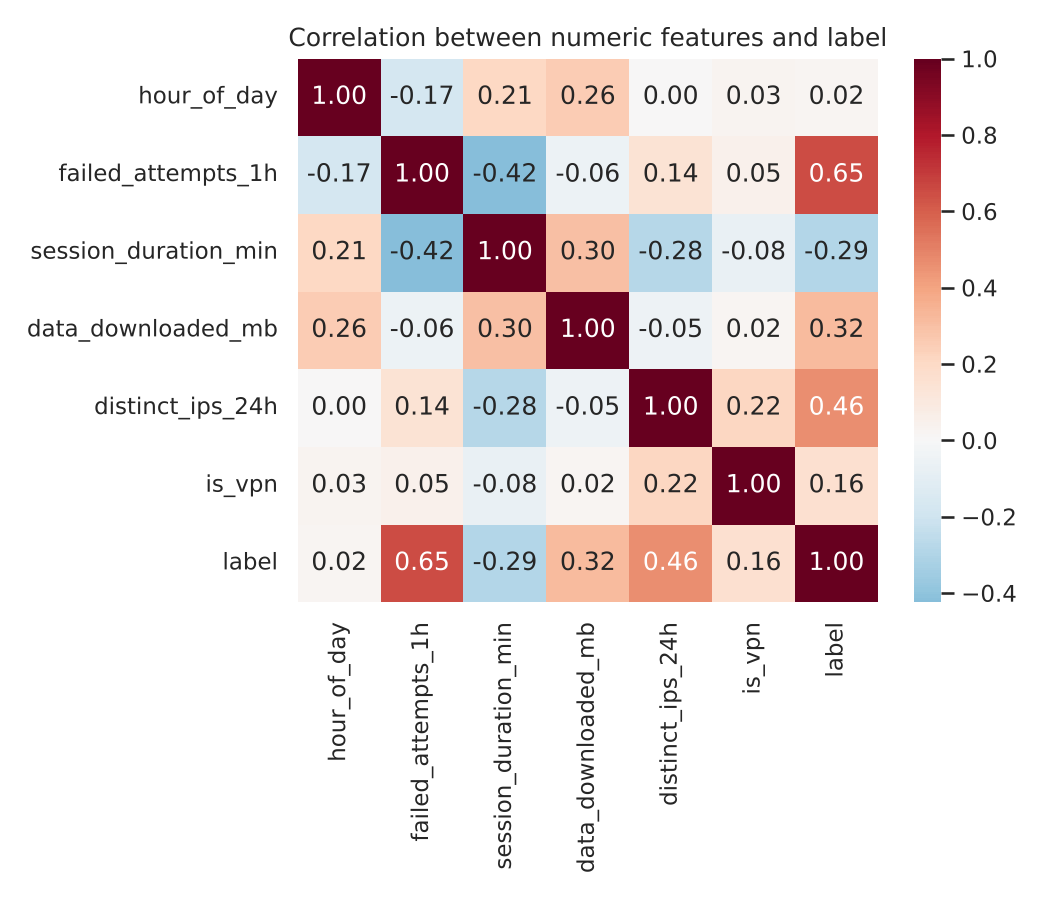

In [6]:
from IPython.display import Image, display

display(Image(filename="../outputs/plots/01_class_balance.png"))
display(Image(filename="../outputs/plots/02_attack_type_frequency.png"))
display(Image(filename="../outputs/plots/03_feature_distributions.png"))
display(Image(filename="../outputs/plots/04_hourly_pattern.png"))
display(Image(filename="../outputs/plots/05_suspicious_rate_by_category.png"))
display(Image(filename="../outputs/plots/06_correlation_heatmap.png"))

## Task 3: Basic Machine Learning-Based Threat Classification

Trains two classic ML models to label a login as normal (0) or
suspicious (1):
- Logistic Regression  (simple, easy to explain)
- Decision Tree        (captures rules like "failed > 5 AND night")
Evaluated with accuracy, precision, recall and F1. In security, recall
(how many attacks we catch) and precision (how many alerts are real)
matter far more than plain accuracy, because the data is imbalanced.

In [7]:
import json
import time

import joblib
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, precision_score, recall_score)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from common import PLOT_DIR, RESULT_DIR, ROOT, SEED, build_preprocessor, load_data, split


def evaluate(name, model, X_train, X_test, y_train, y_test):
    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    pred = model.predict(X_test)
    predict_time = time.perf_counter() - start

    metrics = {
        "model": name,
        "accuracy": round(accuracy_score(y_test, pred), 4),
        "precision": round(precision_score(y_test, pred), 4),
        "recall": round(recall_score(y_test, pred), 4),
        "f1": round(f1_score(y_test, pred), 4),
        "train_time_s": round(train_time, 4),
        "predict_time_ms_per_1k": round(predict_time / len(X_test) * 1000 * 1000, 3),
    }
    print(f"\n===== {name} =====")
    print(classification_report(y_test, pred, target_names=["Normal", "Suspicious"], digits=3))
    return metrics, pred


def main():
    df = load_data()
    X_train, X_test, y_train, y_test = split(df)
    print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows")

    models = {
        "Logistic Regression": Pipeline([
            ("prep", build_preprocessor()),
            ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
        ]),
        # max_depth limits the tree so it doesn't just memorise the training data
        "Decision Tree": Pipeline([
            ("prep", build_preprocessor()),
            ("clf", DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=SEED)),
        ]),
    }

    results = []
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, (name, model) in zip(axes, models.items()):
        metrics, pred = evaluate(name, model, X_train, X_test, y_train, y_test)
        results.append(metrics)
        ConfusionMatrixDisplay.from_predictions(
            y_test, pred, display_labels=["Normal", "Suspicious"], cmap="Blues", ax=ax, colorbar=False)
        ax.set_title(name)
        joblib.dump(model, ROOT / "outputs" / f"{name.lower().replace(' ', '_')}.joblib")
    fig.suptitle("Confusion matrices - classic ML models")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / "07_ml_confusion_matrices.png", dpi=150)
    plt.close(fig)

    # Which features does the decision tree rely on most?
    tree = models["Decision Tree"]
    names = tree.named_steps["prep"].get_feature_names_out()
    importance = pd.Series(tree.named_steps["clf"].feature_importances_, index=names)
    importance = importance[importance > 0].sort_values()
    importance.index = [i.split("__")[1] for i in importance.index]
    fig, ax = plt.subplots(figsize=(7, 4.5))
    importance.plot.barh(ax=ax, color="#55A868")
    ax.set_title("Decision Tree - feature importance")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / "08_feature_importance.png", dpi=150)
    plt.close(fig)
    print("\nTop features (Decision Tree):")
    print(importance.sort_values(ascending=False).head(6).round(3))

    table = pd.DataFrame(results)
    table.to_csv(RESULT_DIR / "ml_results.csv", index=False)
    with open(RESULT_DIR / "ml_results.json", "w") as f:
        json.dump(results, f, indent=2)
    print("\n", table.to_string(index=False))


if __name__ == "__main__":
    main()

Train: 3750 rows | Test: 1250 rows

===== Logistic Regression =====
              precision    recall  f1-score   support

      Normal      0.983     0.989     0.986      1000
  Suspicious      0.955     0.932     0.943       250

    accuracy                          0.978      1250
   macro avg      0.969     0.961     0.965      1250
weighted avg      0.977     0.978     0.977      1250


===== Decision Tree =====
              precision    recall  f1-score   support

      Normal      0.975     0.997     0.986      1000
  Suspicious      0.987     0.896     0.939       250

    accuracy                          0.977      1250
   macro avg      0.981     0.947     0.962      1250
weighted avg      0.977     0.977     0.976      1250




Top features (Decision Tree):
failed_attempts_1h      0.485
distinct_ips_24h        0.186
data_downloaded_mb      0.176
session_duration_min    0.097
hour_of_day             0.027
location_foreign        0.019
dtype: float64

               model  accuracy  precision  recall     f1  train_time_s  predict_time_ms_per_1k
Logistic Regression    0.9776     0.9549   0.932 0.9433        0.0258                   5.733
      Decision Tree    0.9768     0.9868   0.896 0.9392        0.0250                   6.231


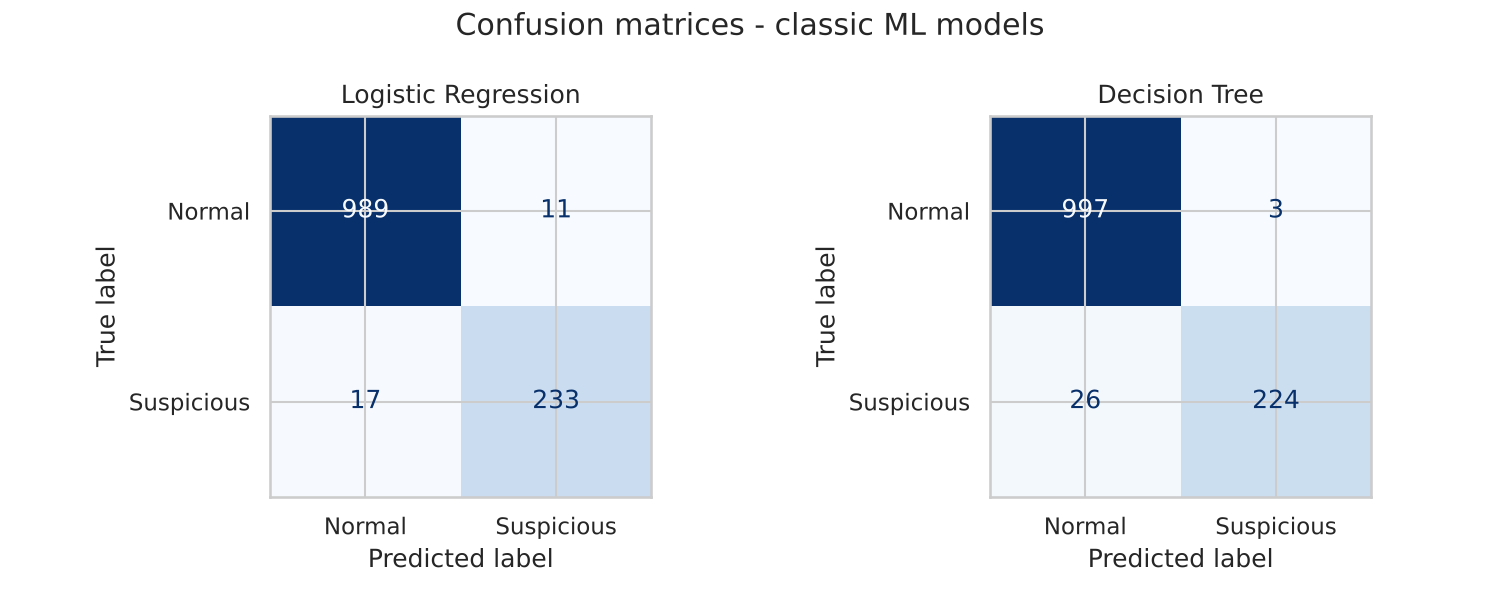

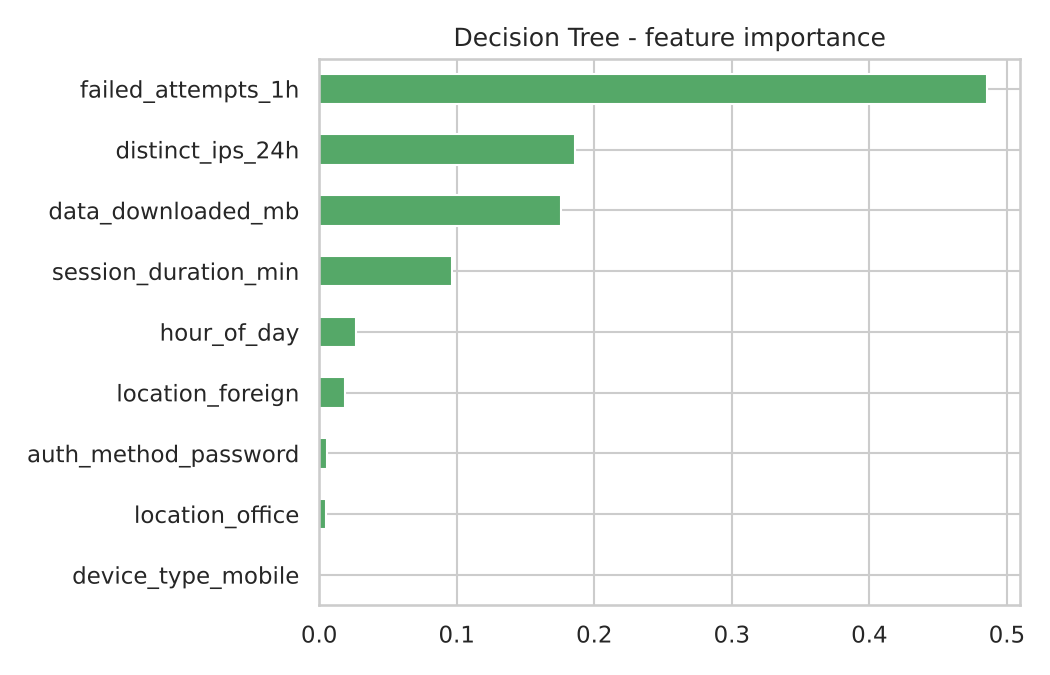

In [8]:
from IPython.display import Image, display

display(Image(filename="../outputs/plots/07_ml_confusion_matrices.png"))
display(Image(filename="../outputs/plots/08_feature_importance.png"))

## Task 4: Deep Learning Prototype and ML vs DL Comparison

Trains a small neural network (scikit-learn MLPClassifier) on the exact
same split and preprocessing as Task 3, then compares it with the
classic models on:
- detection accuracy (accuracy / precision / recall / F1)
- training time and prediction speed
- practical feasibility (discussed in the report)
Each model is trained 3 times and the training time is averaged, because
a single timing on a laptop is noisy.

In [9]:
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from common import PLOT_DIR, RESULT_DIR, SEED, build_preprocessor, load_data, split

RUNS = 3


def make_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
        "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=SEED),
        # 2 hidden layers (32 -> 16 neurons), ReLU, Adam optimiser, early stopping
        # so it stops once the validation score stops improving.
        "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu",
                                              solver="adam", alpha=1e-3, max_iter=300,
                                              early_stopping=True, random_state=SEED),
    }


def main():
    df = load_data()
    X_train, X_test, y_train, y_test = split(df)

    rows = []
    mlp_model = None
    for name, clf in make_models().items():
        times = []
        for _ in range(RUNS):
            model = Pipeline([("prep", build_preprocessor()), ("clf", clf)])
            start = time.perf_counter()
            model.fit(X_train, y_train)
            times.append(time.perf_counter() - start)

        start = time.perf_counter()
        pred = model.predict(X_test)
        predict_time = time.perf_counter() - start

        rows.append({
            "model": name,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred),
            "train_time_s": np.mean(times),
            "predict_time_ms_per_1k": predict_time / len(X_test) * 1e6,
        })
        if name.startswith("Neural"):
            mlp_model = model

    table = pd.DataFrame(rows).round(4)
    table.to_csv(RESULT_DIR / "ml_vs_dl_comparison.csv", index=False)
    print(table.to_string(index=False))

    mlp = mlp_model.named_steps["clf"]
    print(f"\nMLP stopped after {mlp.n_iter_} epochs (early stopping).")

    # ---- Plot: metric comparison -------------------------------------------
    melted = table.melt(id_vars="model", value_vars=["accuracy", "precision", "recall", "f1"],
                        var_name="metric", value_name="score")
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for i, (model_name, grp) in enumerate(melted.groupby("model", sort=False)):
        x = np.arange(4) + (i - 1) * 0.27
        bars = ax.bar(x, grp["score"], width=0.27, label=model_name)
        for b in bars:
            ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.005,
                    f"{b.get_height():.3f}", ha="center", fontsize=7)
    ax.set_xticks(np.arange(4))
    ax.set_xticklabels(["Accuracy", "Precision", "Recall", "F1"])
    ax.set_ylim(min(0.8, melted["score"].min() - 0.03), 1.02)
    ax.set_title("Detection performance: classic ML vs neural network")
    ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / "09_ml_vs_dl_metrics.png", dpi=150)
    plt.close(fig)

    # ---- Plot: training time ----------------------------------------------
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.barh(table["model"], table["train_time_s"], color=["#4C72B0", "#55A868", "#C44E52"])
    for i, v in enumerate(table["train_time_s"]):
        ax.text(v, i, f"  {v:.3f}s", va="center")
    ax.set_xlabel(f"Average training time over {RUNS} runs (seconds)")
    ax.set_title("Training cost")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / "10_training_time.png", dpi=150)
    plt.close(fig)

    # ---- Plot: MLP learning curve ------------------------------------------
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(mlp.loss_curve_, label="training loss")
    ax2 = ax.twinx()
    ax2.plot(mlp.validation_scores_, color="#C44E52", label="validation accuracy")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax2.set_ylabel("Validation accuracy")
    ax.set_title("Neural network training curve")
    fig.legend(loc="center right", bbox_to_anchor=(0.88, 0.5))
    fig.tight_layout()
    fig.savefig(PLOT_DIR / "11_mlp_training_curve.png", dpi=150)
    plt.close(fig)
    print("Plots saved.")


if __name__ == "__main__":
    main()

               model  accuracy  precision  recall     f1  train_time_s  predict_time_ms_per_1k
 Logistic Regression    0.9776     0.9549   0.932 0.9433        0.0265                  5.5061
       Decision Tree    0.9768     0.9868   0.896 0.9392        0.0239                  5.5467
Neural Network (MLP)    0.9888     0.9836   0.960 0.9717        0.4157                  6.3820

MLP stopped after 30 epochs (early stopping).


Plots saved.


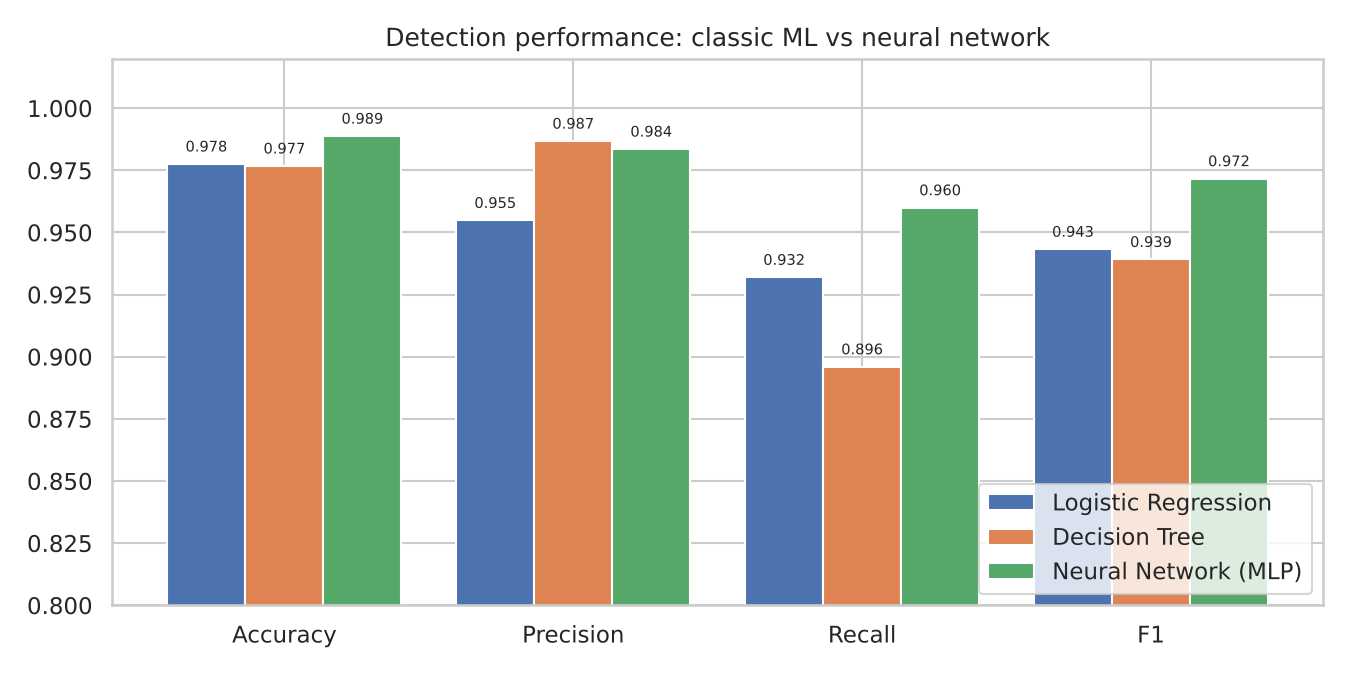

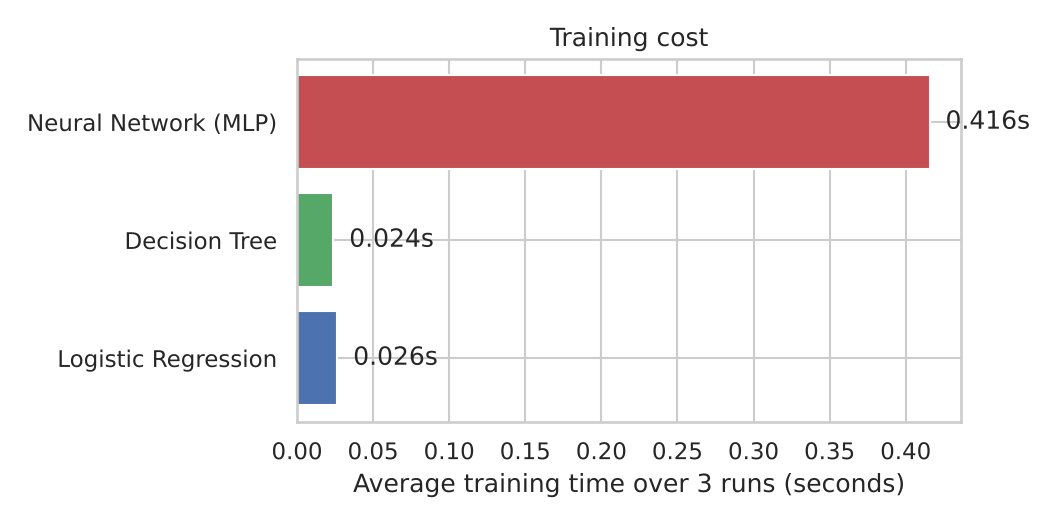

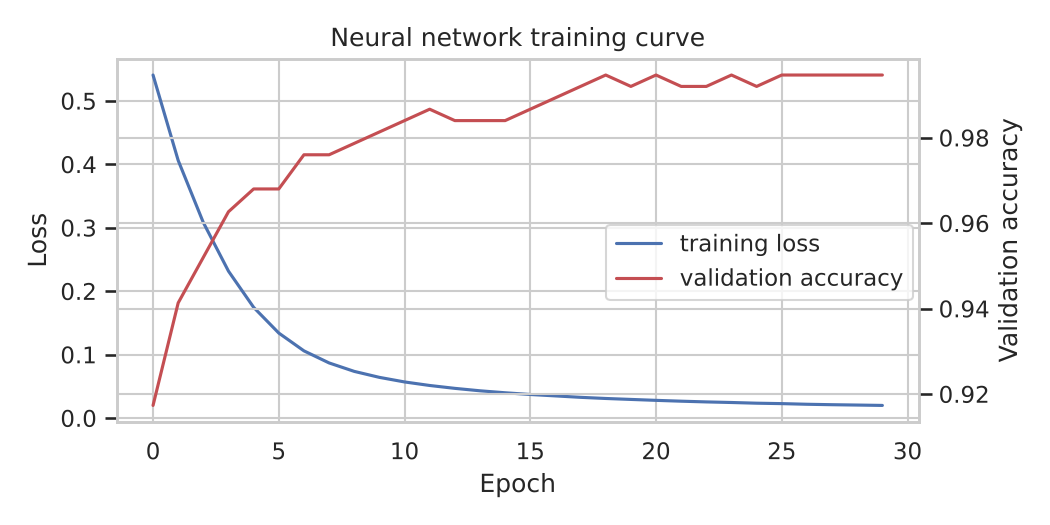

In [10]:
from IPython.display import Image, display

display(Image(filename="../outputs/plots/09_ml_vs_dl_metrics.png"))
display(Image(filename="../outputs/plots/10_training_time.png"))
display(Image(filename="../outputs/plots/11_mlp_training_curve.png"))

## Task 5: Ethical Reflection and AI Challenges

Two experiments:
A) False positives block legitimate users
We move the decision threshold of the Logistic Regression model from
0.05 to 0.95 and count, at each step, how many genuine users would be
blocked and how many attacks would slip through.
B) Biased data leads to unfair decisions
In our training data almost every "foreign" login is an attack, because
genuine staff rarely log in from abroad. We test the model on 300
genuine employees working from abroad and measure how many get blocked.
Then we retrain WITHOUT the location feature and compare.

In [11]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, recall_score
from sklearn.pipeline import Pipeline

from common import (CATEGORICAL, DATA_DIR, NUMERIC, PLOT_DIR, RESULT_DIR, SEED,
                    build_preprocessor, load_data, split)


def lr_model(categorical=CATEGORICAL):
    return Pipeline([
        ("prep", build_preprocessor(categorical=categorical)),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
    ])


def threshold_experiment(model, X_test, y_test):
    proba = model.predict_proba(X_test)[:, 1]
    rows = []
    for t in np.round(np.arange(0.05, 0.96, 0.05), 2):
        pred = (proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
        rows.append({
            "threshold": t,
            "legit_users_blocked": fp,
            "false_positive_rate": fp / (fp + tn),
            "attacks_missed": fn,
            "recall": tp / (tp + fn),
            "f1": f1_score(y_test, pred),
        })
    table = pd.DataFrame(rows).round(4)
    table.to_csv(RESULT_DIR / "threshold_tradeoff.csv", index=False)
    print("\n--- Experiment A: threshold trade-off ---")
    print(table[table["threshold"].isin([0.1, 0.2, 0.3, 0.5, 0.7, 0.9])].to_string(index=False))

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(table["threshold"], table["legit_users_blocked"], marker="o",
            color="#C44E52", label="Genuine users blocked (false positives)")
    ax.plot(table["threshold"], table["attacks_missed"], marker="s",
            color="#4C72B0", label="Attacks missed (false negatives)")
    ax.axvline(0.5, ls="--", color="grey")
    ax.text(0.51, ax.get_ylim()[1] * 0.9, "default 0.5", color="grey")
    ax.set_xlabel("Decision threshold (probability needed to flag a login)")
    ax.set_ylabel(f"Count in test set (n={len(y_test)})")
    ax.set_title("Strict vs relaxed detection: who pays the price?")
    ax.legend()
    fig.tight_layout()
    fig.savefig(PLOT_DIR / "12_threshold_tradeoff.png", dpi=150)
    plt.close(fig)
    return table


def bias_experiment(df, X_train, X_test, y_train, y_test):
    travellers = pd.read_csv(DATA_DIR / "foreign_travellers.csv")
    X_trav = travellers[CATEGORICAL + NUMERIC]

    # How (un)balanced is the training data for "foreign"?
    train = X_train.assign(label=y_train.values)
    foreign_train = train[train["location"] == "foreign"]
    print("\n--- Experiment B: bias from skewed data ---")
    print(f"'foreign' rows in training data: {len(foreign_train)} "
          f"-> {foreign_train['label'].mean():.1%} of them are attacks")

    results = []
    variants = {
        "With location feature": CATEGORICAL,
        "Location feature removed": [c for c in CATEGORICAL if c != "location"],
    }
    for name, cats in variants.items():
        model = lr_model(cats).fit(X_train, y_train)
        test_pred = model.predict(X_test)
        trav_pred = model.predict(X_trav)
        # false positive rate for normal users in the main test set, split by location
        test = X_test.assign(label=y_test.values, pred=test_pred)
        normal = test[test["label"] == 0]
        results.append({
            "model": name,
            "overall_recall": recall_score(y_test, test_pred),
            "overall_f1": f1_score(y_test, test_pred),
            "fpr_office_home_users": normal[normal["location"] != "foreign"]["pred"].mean(),
            "genuine_travellers_blocked_pct": trav_pred.mean(),
            "genuine_travellers_blocked": int(trav_pred.sum()),
        })
    table = pd.DataFrame(results).round(4)
    table.to_csv(RESULT_DIR / "bias_experiment.csv", index=False)
    print(table.to_string(index=False))

    fig, ax = plt.subplots(figsize=(8, 4.2))
    x = np.arange(len(table))
    ax.bar(x - 0.2, table["fpr_office_home_users"] * 100, width=0.4,
           label="Office/home genuine users blocked (%)", color="#4C72B0")
    ax.bar(x + 0.2, table["genuine_travellers_blocked_pct"] * 100, width=0.4,
           label="Genuine foreign travellers blocked (%)", color="#C44E52")
    for i, r in table.iterrows():
        ax.text(i - 0.2, r["fpr_office_home_users"] * 100 + 0.5,
                f"{r['fpr_office_home_users']*100:.1f}%", ha="center")
        ax.text(i + 0.2, r["genuine_travellers_blocked_pct"] * 100 + 0.5,
                f"{r['genuine_travellers_blocked_pct']*100:.1f}%", ha="center")
    ax.set_ylim(0, table["genuine_travellers_blocked_pct"].max() * 100 * 1.3)
    ax.set_xticks(x)
    ax.set_xticklabels(table["model"])
    ax.set_ylabel("% of genuine users wrongly blocked")
    ax.set_title("Same behaviour, different treatment: effect of biased training data")
    ax.legend(loc="upper right")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / "13_bias_experiment.png", dpi=150)
    plt.close(fig)
    return table


def main():
    df = load_data()
    X_train, X_test, y_train, y_test = split(df)
    model = lr_model().fit(X_train, y_train)
    threshold_experiment(model, X_test, y_test)
    bias_experiment(df, X_train, X_test, y_train, y_test)
    print("\nPlots saved.")


if __name__ == "__main__":
    main()


--- Experiment A: threshold trade-off ---
 threshold  legit_users_blocked  false_positive_rate  attacks_missed  recall     f1
       0.1                   55                0.055               7   0.972 0.8869
       0.2                   29                0.029               9   0.964 0.9269
       0.3                   18                0.018               9   0.964 0.9470
       0.5                   11                0.011              17   0.932 0.9433
       0.7                    6                0.006              27   0.892 0.9311
       0.9                    2                0.002              50   0.800 0.8850



--- Experiment B: bias from skewed data ---
'foreign' rows in training data: 474 -> 87.3% of them are attacks


                   model  overall_recall  overall_f1  fpr_office_home_users  genuine_travellers_blocked_pct  genuine_travellers_blocked
   With location feature           0.932      0.9433                 0.0092                          0.1000                          30
Location feature removed           0.880      0.9091                 0.0142                          0.0067                           2



Plots saved.


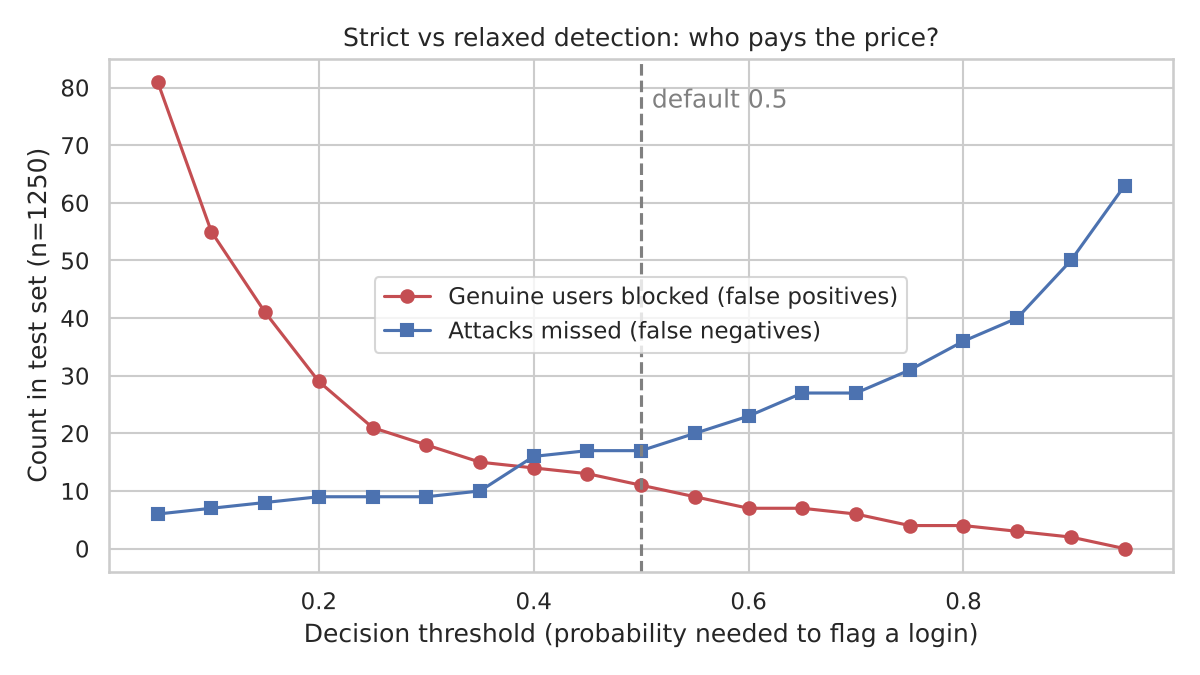

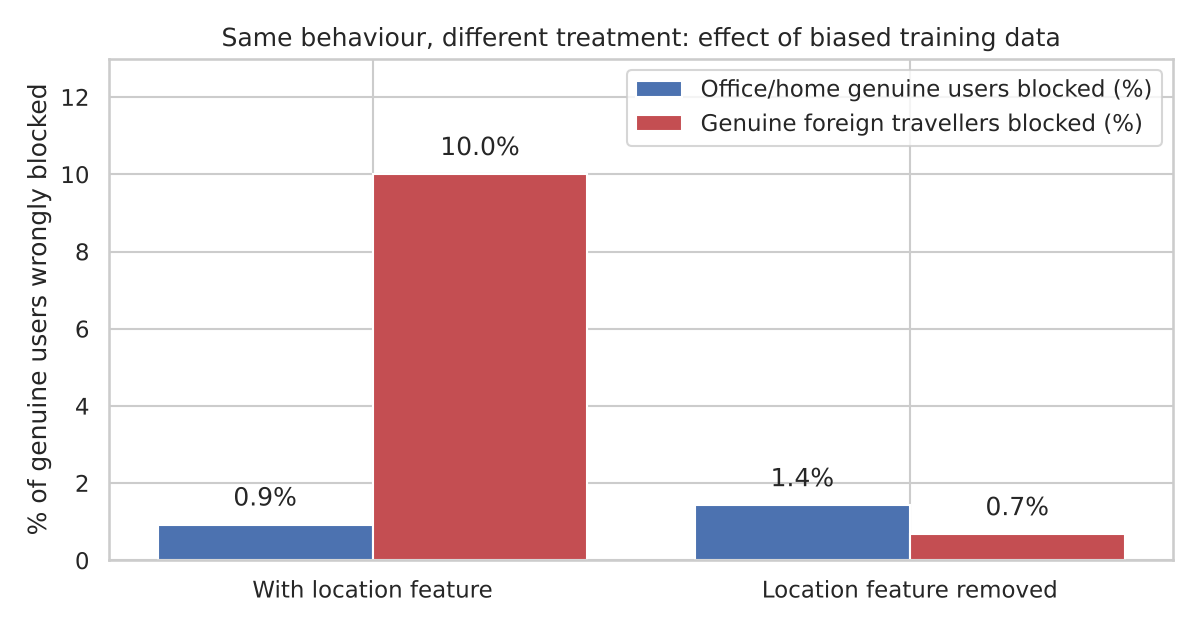

In [12]:
from IPython.display import Image, display

display(Image(filename="../outputs/plots/12_threshold_tradeoff.png"))
display(Image(filename="../outputs/plots/13_bias_experiment.png"))

## Conclusion

- All three models detect suspicious logins well (F1 above 0.93). The neural network is best (F1 0.972) but is slower to train and harder to explain.
- Lowering the decision threshold catches a few more attacks but blocks many more genuine users.
- Biased history (most foreign logins were attacks) made the model block 10% of genuine employees working abroad. Removing the location feature cut this to 0.7%, at a small cost in recall.

Full discussion is in the technical report (`report/` folder).